In [3]:

import pandas as pd
from google.colab import files
import io

# Upload your pharma sales CSV file
uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display the first five rows
print(df.head())

# Check the column names
print(df.columns.tolist())

# Check the dataset dimensions
print("Dataset shape:", df.shape)


Saving Sales analysis.csv to Sales analysis.csv
        datum   M01AB    M01AE    N02BA     N02BE   N05B  N05C    R03    R06  \
0  31-01-2014  127.69   99.090  152.100   878.030  354.0    50  112.0   48.2   
1  28-02-2014  133.32  126.050  177.000  1001.900  347.0    31  122.0   36.2   
2  31-03-2014  137.44   92.950  147.655   779.275  232.0    20  112.0   85.4   
3  30-04-2014  113.10   89.475  130.900   698.500  209.0    18   97.0   73.7   
4  31-05-2014  101.79  119.933  132.100   628.780  270.0    23  107.0  123.7   

   Total Sales Volume  
0            1821.110  
1            1974.470  
2            1606.720  
3            1429.675  
4            1506.303  
['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06', 'Total Sales Volume']
Dataset shape: (70, 10)


In [4]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Identify the medicine category columns
category_cols = [
    col for col in df.columns
    if col != "datum"
]

# Convert categories to numeric values
df[category_cols] = df[category_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Calculate total sales volume per month
df["Total_Sales_Volume"] = df[
    category_cols
].sum(axis=1, min_count=len(category_cols))

# Display monthly totals
print(
    df[["datum", "Total_Sales_Volume"]].head(10)
)

# Total sales volume across the dataset
print(
    "Overall sales volume:",
    df["Total_Sales_Volume"].sum()
)

Duplicate rows: 0
        datum  Total_Sales_Volume
0  31-01-2014            3642.220
1  28-02-2014            3948.940
2  31-03-2014            3213.440
3  30-04-2014            2859.350
4  31-05-2014            3012.606
5  30-06-2014            2780.410
6  31-07-2014            2664.740
7  31-08-2014            2998.040
8  30-09-2014            3629.188
9  31-10-2014            6293.812
Overall sales volume: 253171.54800000004


In [5]:
category_totals_python = (
    df[category_cols]
    .sum(min_count=len(df))
    .sort_values(ascending=False)
)

print(category_totals_python)

Total Sales Volume    126585.774
N02BE                  62477.945
N05B                   18348.300
R03                    11737.250
M01AB                  10499.440
M01AE                   8156.000
N02BA                   8051.459
R06                     6066.380
N05C                    1249.000
dtype: float64


/tmp/ipykernel_3804/3190524879.py:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["datum"] = pd.to_datetime(df["datum"])


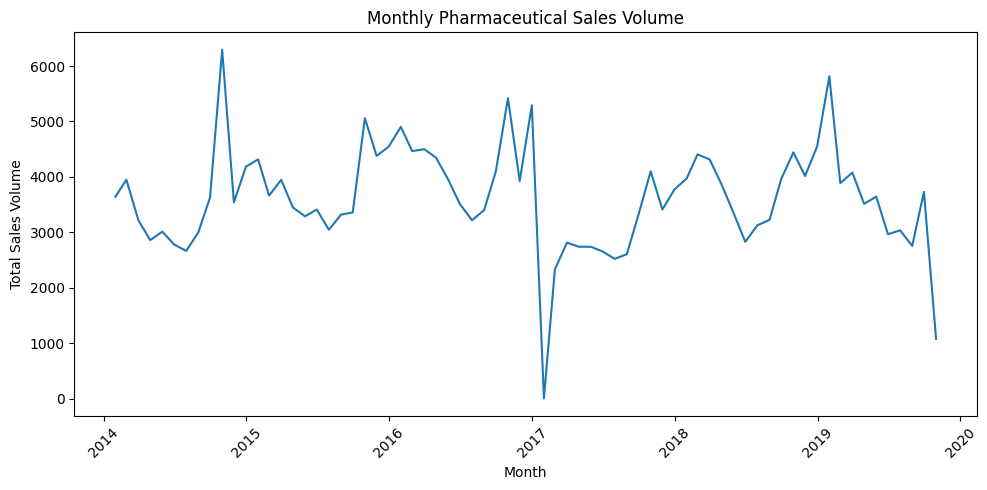

In [6]:
import matplotlib.pyplot as plt

df["datum"] = pd.to_datetime(df["datum"])

df = df.sort_values("datum")

plt.figure(figsize=(10, 5))

plt.plot(
    df["datum"],
    df["Total_Sales_Volume"]
)

plt.title("Monthly Pharmaceutical Sales Volume")
plt.xlabel("Month")
plt.ylabel("Total Sales Volume")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

adding sql to this

In [7]:
# Convert the data into a longer table
long_df = df.melt(
    id_vars=["datum"],
    value_vars=category_cols,
    var_name="Category",
    value_name="Sales_Volume"
)

print(long_df.head())

       datum Category  Sales_Volume
0 2014-01-31    M01AB        127.69
1 2014-02-28    M01AB        133.32
2 2014-03-31    M01AB        137.44
3 2014-04-30    M01AB        113.10
4 2014-05-31    M01AB        101.79


In [9]:
import sqlite3

conn = sqlite3.connect("pharma_sales.db")

long_df.to_sql(
    "pharma_sales",
    conn,
    if_exists="replace",
    index=False
)

print("SQL table created successfully.")

SQL table created successfully.


In [16]:

# Display all column names in your dataset
print(df.columns.tolist())

print(pd.read_sql_query(
    "PRAGMA table_info(pharma_sales);",
    conn
))


for i, col in enumerate(df.columns):
    print(i, repr(col))



print(df.head(3))
print(df.columns.tolist())


['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06', 'Total Sales Volume', 'Total_Sales_Volume']
    cid                name       type  notnull dflt_value  pk
0     0               datum  TIMESTAMP        0       None   0
1     1               M01AB       REAL        0       None   0
2     2               M01AE       REAL        0       None   0
3     3               N02BA       REAL        0       None   0
4     4               N02BE       REAL        0       None   0
5     5                N05B       REAL        0       None   0
6     6                N05C    INTEGER        0       None   0
7     7                 R03       REAL        0       None   0
8     8                 R06       REAL        0       None   0
9     9  Total Sales Volume       REAL        0       None   0
10   10  Total_Sales_Volume       REAL        0       None   0
0 'datum'
1 'M01AB'
2 'M01AE'
3 'N02BA'
4 'N02BE'
5 'N05B'
6 'N05C'
7 'R03'
8 'R06'
9 'Total Sales Volume'
10 'Total_Sales_V

In [18]:

query = """
SELECT
    SUM(M01AB) AS M01AB_Total,
    SUM(M01AE) AS M01AE_Total,
    SUM(N02BA) AS N02BA_Total,
    SUM(N02BE) AS N02BE_Total,
    SUM(N05B) AS N05B_Total,
    SUM(N05C) AS N05C_Total,
    SUM(R03) AS R03_Total,
    SUM(R06) AS R06_Total
FROM pharma_sales;
"""

result = pd.read_sql_query(query, conn)
print(result.T)


                     0
M01AB_Total  10499.440
M01AE_Total   8156.000
N02BA_Total   8051.459
N02BE_Total  62477.945
N05B_Total   18348.300
N05C_Total    1249.000
R03_Total    11737.250
R06_Total     6066.380


In [19]:

query = """
SELECT
    SUM("Total Sales Volume") AS Original_Total,
    SUM(Total_Sales_Volume) AS Underscore_Total,
    COUNT(*) AS Number_of_Rows
FROM pharma_sales;
"""

result = pd.read_sql_query(query, conn)
print(result)


   Original_Total  Underscore_Total  Number_of_Rows
0      126585.774        253171.548              70


In [20]:

query = """
SELECT
    datum,
    M01AB + M01AE + N02BA + N02BE +
    N05B + N05C + R03 + R06 AS Calculated_Total
FROM pharma_sales
ORDER BY datum;
"""

monthly_sales = pd.read_sql_query(query, conn)
print(monthly_sales.head(10))


                 datum  Calculated_Total
0  2014-01-31 00:00:00          1821.110
1  2014-02-28 00:00:00          1974.470
2  2014-03-31 00:00:00          1606.720
3  2014-04-30 00:00:00          1429.675
4  2014-05-31 00:00:00          1506.303
5  2014-06-30 00:00:00          1390.205
6  2014-07-31 00:00:00          1332.370
7  2014-08-31 00:00:00          1499.020
8  2014-09-30 00:00:00          1814.594
9  2014-10-31 00:00:00          3146.906


Which categories have the highest sales volume?

In [23]:

query1 = """
SELECT
    'M01AB' AS Category, SUM(M01AB) AS Total_Sales
FROM pharma_sales

UNION ALL

SELECT 'M01AE', SUM(M01AE) FROM pharma_sales
UNION ALL
SELECT 'N02BA', SUM(N02BA) FROM pharma_sales
UNION ALL
SELECT 'N02BE', SUM(N02BE) FROM pharma_sales
UNION ALL
SELECT 'N05B', SUM(N05B) FROM pharma_sales
UNION ALL
SELECT 'N05C', SUM(N05C) FROM pharma_sales
UNION ALL
SELECT 'R03', SUM(R03) FROM pharma_sales
UNION ALL
SELECT 'R06', SUM(R06) FROM pharma_sales

ORDER BY Total_Sales DESC;
"""

result1 = pd.read_sql_query(query1, conn)
print(result1)


  Category  Total_Sales
0    N02BE    62477.945
1     N05B    18348.300
2      R03    11737.250
3    M01AB    10499.440
4    M01AE     8156.000
5    N02BA     8051.459
6      R06     6066.380
7     N05C     1249.000


What are the monthly totals?

In [24]:

query2 = """
SELECT
    datum AS Month,
    SUM(
        M01AB + M01AE + N02BA + N02BE +
        N05B + N05C + R03 + R06
    ) AS Monthly_Total_Sales
FROM pharma_sales
GROUP BY datum
ORDER BY datum;
"""

result2 = pd.read_sql_query(query2, conn)
print(result2)


                  Month  Monthly_Total_Sales
0   2014-01-31 00:00:00             1821.110
1   2014-02-28 00:00:00             1974.470
2   2014-03-31 00:00:00             1606.720
3   2014-04-30 00:00:00             1429.675
4   2014-05-31 00:00:00             1506.303
..                  ...                  ...
65  2019-06-30 00:00:00             1482.407
66  2019-07-31 00:00:00             1517.941
67  2019-08-31 00:00:00             1377.779
68  2019-09-30 00:00:00             1864.387
69  2019-10-31 00:00:00              538.600

[70 rows x 2 columns]


What is the average monthly sales volume for each category?

In [25]:

query3 = """
SELECT
    'M01AB' AS Category, AVG(M01AB) AS Average_Monthly_Sales
FROM pharma_sales

UNION ALL

SELECT 'M01AE', AVG(M01AE) FROM pharma_sales
UNION ALL
SELECT 'N02BA', AVG(N02BA) FROM pharma_sales
UNION ALL
SELECT 'N02BE', AVG(N02BE) FROM pharma_sales
UNION ALL
SELECT 'N05B', AVG(N05B) FROM pharma_sales
UNION ALL
SELECT 'N05C', AVG(N05C) FROM pharma_sales
UNION ALL
SELECT 'R03', AVG(R03) FROM pharma_sales
UNION ALL
SELECT 'R06', AVG(R06) FROM pharma_sales

ORDER BY Average_Monthly_Sales DESC;
"""

result3 = pd.read_sql_query(query3, conn)
print(result3)


  Category  Average_Monthly_Sales
0    N02BE             892.542071
1     N05B             262.118571
2      R03             167.675000
3    M01AB             149.992000
4    M01AE             116.514286
5    N02BA             115.020843
6      R06              86.662571
7     N05C              17.842857
